<a href="https://colab.research.google.com/github/Nasim-Amani/solar/blob/main/3Exploratory_Analysis_Correlation_and_Thermal_Response.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset: `solar_data_final_columns.csv`

### Overview
Outdoor solar and PV measurements at **1-second resolution**, from **2013-02-15 18:49 to 2013-02-27 13:03** (1,015,991 records).
- **Complete days:** Feb 16–26 (11 days). Feb 15 and Feb 27 are partial; use the `full_day` flag for daily statistics.
- **Time stamps:** no duplicates and no missing values; only 9 isolated missing seconds.

### What was done to get this file
1. **Irradiance offset removed:** the radiation sensor showed a constant **+2.71 W/m²** at night (a sensor offset, not light). This was subtracted from all values, and negatives were set to 0 → `Solar_Rad_clean`.
2. **Daylight defined:** a record is daylight if the 1-min median of `Solar_Rad_clean` is > 1 W/m² → `daylight` flag.
3. **Column screening:** each sensor was checked against irradiance and physical behaviour.
   - **Removed:** `PV_1_SA_I` (always ~0 A, because PV_1 is at open circuit) and `PV_3_Tr_I` (not working consistently).
   - **Kept with a special meaning:** `PV_1_SA_V` and the PV_4 signals (see table).

### Columns

| Column | Meaning | Use |
|---|---|---|
| `Solar_Rad` | Raw irradiance (W/m²) | Reference only |
| `Solar_Rad_clean` | **Irradiance, offset-corrected (W/m²)** | ✅ Main irradiance variable |
| `Amb_Tempr` | Ambient air temperature (°C) | ✅ |
| `Tempr_PV_1`, `Tempr_PV_2`, `Tempr_PV_3` | PV module temperatures (°C) | ✅ |
| `PV_1_SA_V` | **Open-circuit voltage (Voc)** of PV module 1 (V). Confirmed physically (−0.325 %/°C) | ✅ |
| `PV_2_GT_I` | Current of PV module 2 (A). Follows irradiance almost perfectly (r = 0.995) | ✅ |
| `PV_4_Hor_V`, `PV_4_Hor_I`, `PV_4_Hor_P` | Voltage (V), current (A) and power (W) of a small panel **charging a battery through a charge controller** | ⚠️ Reflects battery state, not weather |
| `PV4_state` | PV_4 operating state: `night` / `charging` / `disconnected` | ⚠️ Helper for PV_4 |
| `full_day` | True for complete days (Feb 16–26) | Flag |
| `daylight` | True when there is measurable sunlight | Flag |


### Important Notes

**1. Which irradiance column to use**
Use `Solar_Rad_clean`. The raw column `Solar_Rad` never goes to 0 at night (it shows ~2.7 W/m² because of a sensor error), so it slightly overestimates sunlight at all times.

**2. Selecting daytime records**
About half of the records are night, where most values are zero or constant. Including them in averages or correlations gives misleading results. To keep only records with sunlight:
`day_df = df[df["daylight"]]`

**3. Selecting complete days**
The first day (Feb 15) starts at 18:49 and the last day (Feb 27) ends at 13:03, so they are incomplete.

**4. Small non-zero values at night**
At night, when there is no sunlight, these sensors should read exactly 0, but they show small constant values:
- `PV_2_GT_I` ≈ 0.04 A (its daytime values go up to ~10 A)
- `PV_1_SA_V` ≈ 0.43 V (daytime ~40 V)
- `PV_4_Hor_V` ≈ −0.61 V (daytime up to ~20 V)

These are small sensor errors, about 1–3% of the daytime values. They were **not corrected**. They can be ignored for most work, or subtracted (as was done for irradiance) if exact zero-at-night values are needed.



**5. Sudden drops and peaks in irradiance (interpreted, not confirmed)**
No sky camera or weather observations are available, so the causes below are **assumed** from the shape of the signals.

- **Sharp drops** in `Solar_Rad_clean` and `PV_2_GT_I` (e.g. from 800 to 200 W/m² within seconds) are **assumed to be clouds passing in front of the sun**.
  *Basis:* the drops appear **at the same time in two independent sensors** (the irradiance sensor and the PV_2 current), which makes a sensor fault unlikely. They also occur on some days and not on others, and the module temperatures respond to them a few minutes later.
  *Recommendation:* do not remove them as outliers.

- **Short peaks above the normal clear-day level** (up to 1,022 W/m²) are **assumed to be "cloud enhancement"**: sunlight briefly reflected from the edges of nearby clouds onto the sensor, a known effect in high-resolution solar data.
  *Basis:* they last only seconds and occur on partly cloudy days, next to cloud-related drops, not on fully clear days.
  *Recommendation:* keep them, but be aware they are a possible source of extreme values.

In [16]:
import pandas as pd

df = pd.read_csv("solar_data_final_columns.csv")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1015991 entries, 0 to 1015990
Data columns (total 15 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   DateTime         1015991 non-null  object 
 1   Solar_Rad        1015991 non-null  float64
 2   Solar_Rad_clean  1015991 non-null  float64
 3   Amb_Tempr        1015991 non-null  float64
 4   Tempr_PV_1       1015991 non-null  float64
 5   Tempr_PV_2       1015991 non-null  float64
 6   Tempr_PV_3       1015991 non-null  float64
 7   PV_1_SA_V        1015991 non-null  float64
 8   PV_2_GT_I        1015991 non-null  float64
 9   PV_4_Hor_V       1015991 non-null  float64
 10  PV_4_Hor_I       1015991 non-null  float64
 11  PV_4_Hor_P       1015991 non-null  float64
 12  PV4_state        1015991 non-null  object 
 13  full_day         1015991 non-null  bool   
 14  daylight         1015991 non-null  bool   
dtypes: bool(2), float64(11), object(2)
memory usage: 102.7+ MB


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

df = pd.read_csv("solar_data_final_columns.csv")
df["DateTime"] = pd.to_datetime(df["DateTime"], format="%Y-%m-%d %H:%M:%S")
df = df.set_index("DateTime").sort_index()

VARS = ["Solar_Rad_clean", "PV_2_GT_I", "PV_1_SA_V", "Amb_Tempr",
        "Tempr_PV_1", "Tempr_PV_2", "Tempr_PV_3",
        "PV_4_Hor_V", "PV_4_Hor_I", "PV_4_Hor_P"]
SHORT = {"Solar_Rad_clean": "Solar", "PV_2_GT_I": "PV2_I", "PV_1_SA_V": "PV1_Voc", "Amb_Tempr": "T_amb",
         "Tempr_PV_1": "T_PV1", "Tempr_PV_2": "T_PV2", "Tempr_PV_3": "T_PV3",
         "PV_4_Hor_V": "PV4_V", "PV_4_Hor_I": "PV4_I", "PV_4_Hor_P": "PV4_P"}

print(f"Records : {len(df):,}")
print(f"Period  : {df.index[0]}  ->  {df.index[-1]}")
print(f"Complete days: {df.loc[df['full_day']].index.normalize().nunique()}")
print(f"Daylight share: {df['daylight'].mean():.1%}")
print(f"Missing values in analysed variables: {int(df[VARS].isna().sum().sum())}")

Records : 1,015,991
Period  : 2013-02-15 18:49:44  ->  2013-02-27 13:03:03
Complete days: 11
Daylight share: 48.4%
Missing values in analysed variables: 0


Short names are used in tables and plots, e.g. `GHI` for `Solar_Rad_clean` and `T_PV1` for `Tempr_PV_1`.

- **48.4% of records are daylight.** Roughly half of the data is night, which is why later analyses use daylight records only.

## 1. Descriptive statistics (daylight vs night)

In [18]:
day, night = df["daylight"], ~df["daylight"]
desc = pd.DataFrame({
    "min":        df[VARS].min(),
    "max":        df[VARS].max(),
    "mean_day":   df.loc[day, VARS].mean(),
    "std_day":    df.loc[day, VARS].std(),
    "mean_night": df.loc[night, VARS].mean(),
    "std_night":  df.loc[night, VARS].std(),
}).rename(index=SHORT).round(3)
display(desc)

,min,max,mean_day,std_day,mean_night,std_night
Solar,0.000,1021.691,455.760,281.545,0.039,0.084
PV2_I,-0.014,10.168,4.285,2.690,0.038,0.025
PV1_Voc,0.000,43.112,39.528,3.295,0.431,2.313
T_amb,15.447,31.768,23.376,2.602,20.375,2.025
T_PV1,8.145,62.279,33.397,11.841,13.156,1.940
T_PV2,7.486,56.493,32.313,11.742,12.320,1.942
T_PV3,8.713,59.031,29.828,9.889,13.494,1.892
PV4_V,-0.618,20.821,15.352,5.493,-0.614,0.032
PV4_I,-0.192,1.536,0.106,0.138,0.008,0.034
PV4_P,-2.549,21.452,1.785,2.103,-0.005,0.021


**What this cell does:** summarises each variable separately for **daylight** and **night**: overall minimum and maximum, plus the mean and standard deviation (std) in each period.

**Result and interpretation:**
- **Solar:** daytime mean 456 W/m² (max 1,022 W/m²). At night it is ≈ 0 (mean 0.04 W/m²), which confirms the offset correction worked.
- **PV2_I:** follows the sun, with a daytime mean of 4.3 A (max 10.2 A) and ≈ 0 at night (0.04 A).
- **PV1_Voc:** almost constant during the day (mean 39.5 V). The night values (mean 0.43 V, std 2.3 V) are mostly from **twilight minutes**: Voc rises at very low light, even before the daylight threshold of 1 W/m² is reached.
- **Module temperatures (T_PV1–3):** heat from ~13 °C at night to ~30–33 °C on average during the day (max 56–62 °C). **T_PV3 is the coolest module** (daytime mean 29.8 °C vs 32–33 °C for the others), possibly because of a different mounting or position.
- **T_amb:** varies little (20.4 °C at night, 23.4 °C by day). At night the modules (~13 °C) are about 7 °C **colder than the air**, which is consistent with panels cooling by radiating heat to the night sky.
- **PV4 (V, I, P):** voltage ≈ −0.6 V at night (a small sensor offset), and mean daytime power of only 1.8 W (max 21.5 W), consistent with a small battery-charging panel.

## 2. Daily behaviour of all variables

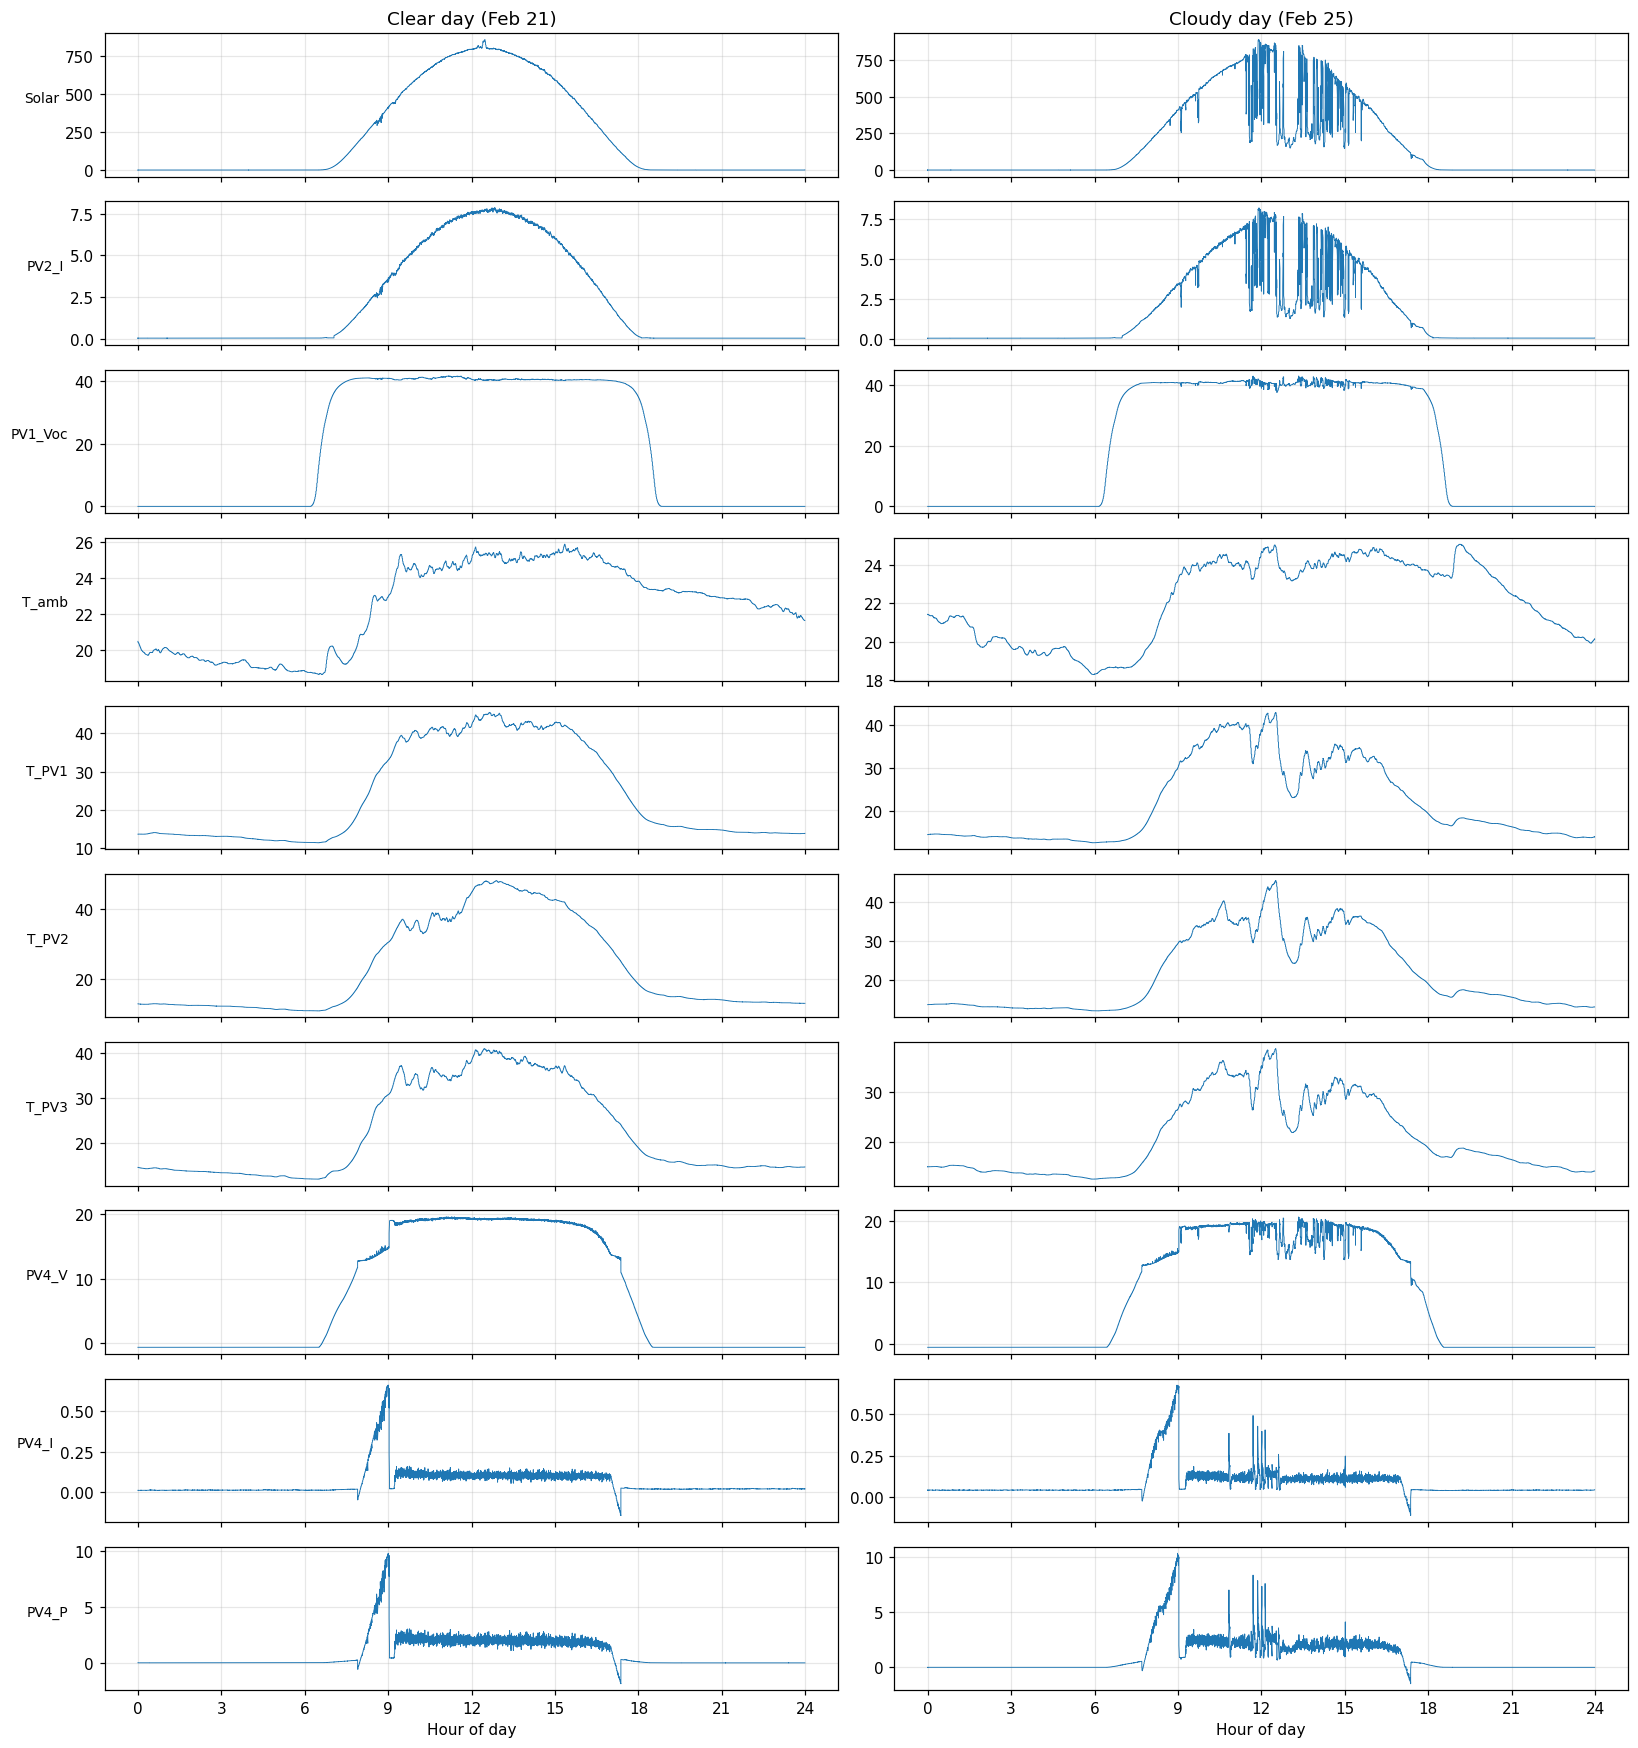

In [19]:
days = {"Clear day (Feb 21)": "2013-02-21", "Cloudy day (Feb 25)": "2013-02-25"}
fig, axes = plt.subplots(len(VARS), 2, figsize=(15, 1.6 * len(VARS)), sharex="col")
for j, (title, d) in enumerate(days.items()):
    x = df.loc[d, VARS].resample("10s").mean()
    hours = x.index.hour + x.index.minute / 60
    for i, col in enumerate(VARS):
        axes[i, j].plot(hours, x[col], lw=0.6)
        if j == 0:
            axes[i, j].set_ylabel(SHORT[col], rotation=0, ha="right", fontsize=9)
    axes[0, j].set_title(title)
    axes[-1, j].set_xticks(range(0, 25, 3))
    axes[-1, j].set_xlabel("Hour of day")
plt.tight_layout()
plt.show()

**What this cell does:** plots all variables (10-s means) on a **clear day** (Feb 21) and a **cloudy day** (Feb 25), to compare how each one responds to the sun and to clouds.

**Interpretation:**
- **Solar and PV2_I** have the same shape on both days. A smooth bell on the clear day, and identical sharp drops on the cloudy day, which confirms that PV2_I closely tracks irradiance.
- **Module temperatures (T_PV1–3)** follow the sun but **more smoothly and with a delay**. On the cloudy day they drop by up to ~15 °C during cloudy periods, but more slowly than irradiance (thermal inertia).
- **PV1_Voc** rises quickly at sunrise to ~40 V and stays almost flat all day. Clouds cause only small ripples, as expected for open-circuit voltage.
- **T_amb** changes slowly (19–26 °C) and responds only weakly to clouds. A short rise after sunset on Feb 25 (~19:00) is not linked to irradiance and may reflect a local weather change.
- **PV4 (V, I, P)** shows the same charging pattern on both days (charging until ~09:00, then disconnected), so its behaviour is driven by the battery, not by the weather. On the cloudy day, clouds only add small dips in voltage and brief spikes in current.

## 3. Correlation analysis

### Methodological choices
- **Daylight data only.** At night most variables are constant or zero. Including night would inflate all correlations simply because of the day–night cycle.
- **1-min means of complete days.** This removes 1-s sensor noise and reduces the very strong autocorrelation of 1-s data, while keeping cloud-induced variability.
- **Three complementary measures:**
  - **Pearson r:** strength of the *linear* relationship.
  - **Spearman ρ:** strength of any *monotonic* relationship (robust to non-linearity and outliers).
  - **Mutual information (MI):** *any* dependence, including non-linear and non-monotonic. For comparability, MI is converted to the **information coefficient of correlation**, IC = √(1 − e^(−2·MI)), which ranges from 0 to 1 and equals |r| for linear-Gaussian relationships.

## 3. Correlation analysis

### How we did it
- **We used daylight data only.** At night almost everything is zero or constant. If we included the night, every variable would look strongly related to every other one, just because they all change between day and night.
- **We used 1-minute averages of the complete days.** The 1-s data is noisy, and neighbouring seconds are almost identical. Averaging over 1 minute removes this noise but still keeps the effect of passing clouds.
- **We used three different measures**, because each one sees relationships differently:
  - **Pearson (r):** shows the *linear* relationship.
  - **Spearman (ρ):** shows any *monotonic* relationship(robust to non-linearity and outliers).
   - **Mutual information (MI):** *any* dependence, including non-linear and non-monotonic. To compare it easily with the other two, MI is converted to the **information coefficient of correlation**, 0–1 scale (called IC): 0 means no relationship and 1 means a very strong one.

### 3.1 Pearson and Spearman correlation

1-min daylight samples used: 7,809


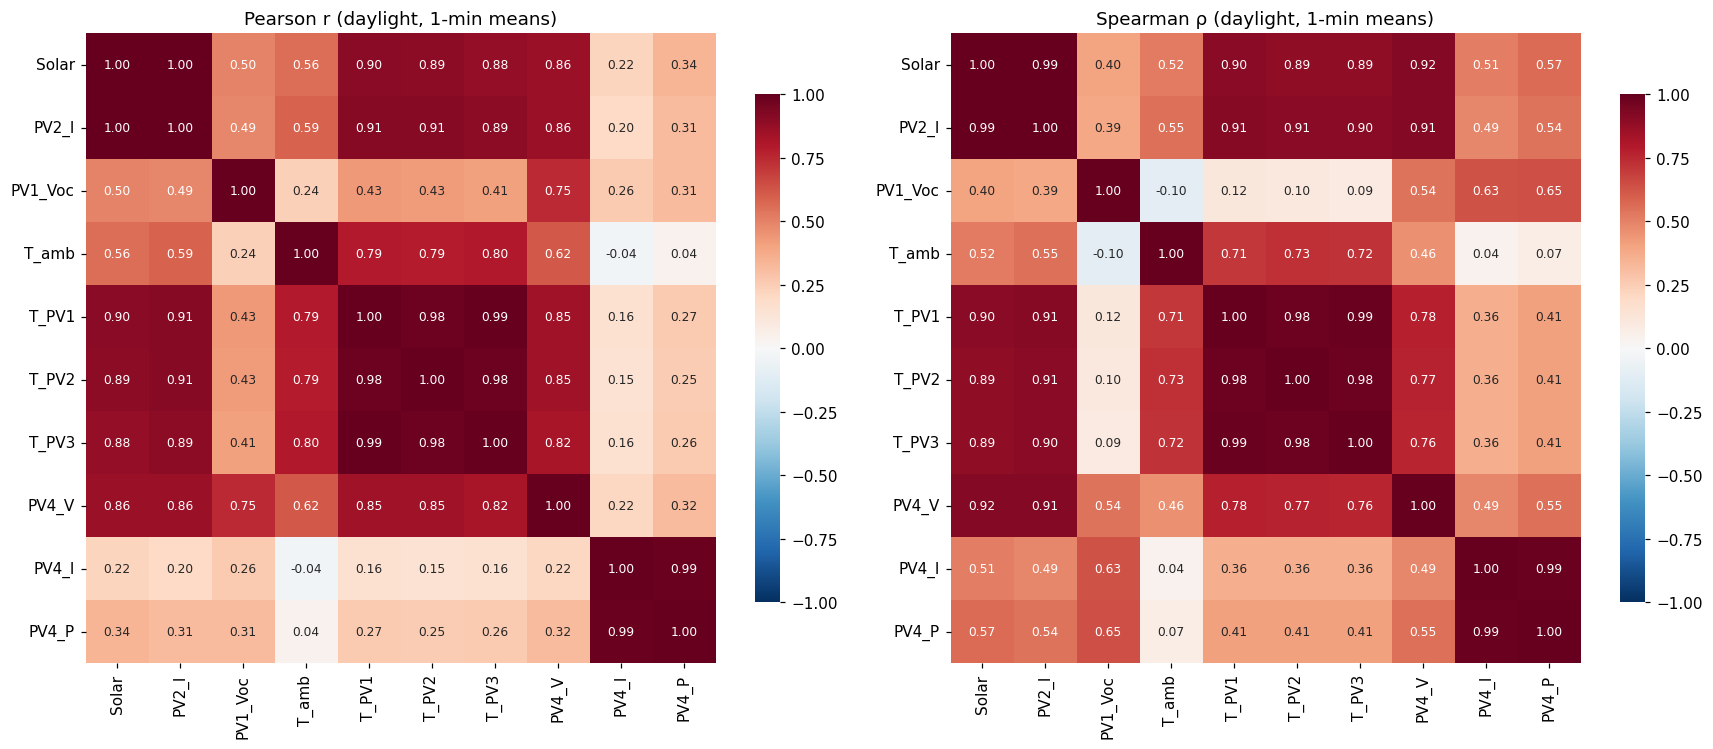

In [20]:
m1 = (df.loc[day & df["full_day"], VARS]
        .resample("1min").mean()
        .dropna()
        .rename(columns=SHORT))
print(f"1-min daylight samples used: {len(m1):,}")

pearson  = m1.corr(method="pearson")
spearman = m1.corr(method="spearman")

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
for a, (name, mat) in zip(ax, [("Pearson r", pearson), ("Spearman ρ", spearman)]):
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                square=True, cbar_kws={"shrink": 0.8}, ax=a, annot_kws={"size": 8})
    a.set_title(f"{name} (daylight, 1-min means)")
    a.grid(False)
plt.tight_layout()
plt.show()

### 3.1 Pearson and Spearman correlation: interpretation

**Irradiance and PV current**
- `Solar` and `PV2_I` are almost perfectly correlated (r = 1.00, ρ = 0.99). The PV_2 current is effectively a **proxy for irradiance**, as expected since a PV module's current is proportional to irradiance.

**Module temperatures**
- `T_PV1`, `T_PV2` and `T_PV3` are strongly correlated with irradiance (r = 0.88–0.90). The three sensors carry largely the **same information**, so one sensor (or their mean) can represent module temperature.
- `T_amb` correlates only moderately with irradiance (r = 0.56) but strongly with module temperatures (r ≈ 0.79–0.80). This is consistent with ambient temperature setting the **baseline**, with irradiance adding the heating on top.

**Open-circuit voltage (PV1_Voc)**
- Pairwise correlations are **misleading** for this variable. Voc correlates *positively* with module temperature (r ≈ 0.43), although physically it *decreases* with temperature (−0.325 %/°C, Section 2 of the previous notebook). The positive value arises because both variables are low at sunrise and sunset, so the shared dependence on irradiance hides the true effect. Spearman correlations near zero (ρ ≈ 0.10) confirm the inconsistency. This shows the limits of pairwise correlation when variables share a common driver.

**PV4 (battery-charging panel)**
- `PV4_V` correlates strongly with irradiance (r = 0.86, ρ = 0.92), mainly because its controller states follow the daily cycle (low voltage while charging in the morning, high voltage when disconnected).
- `PV4_I` and `PV4_P` show weak Pearson correlations (r = 0.22–0.34) but moderate Spearman correlations (ρ = 0.51–0.57). This points to a **non-linear, regime-dependent** relationship caused by the charge controller.

### 3.2 Mutual information (non-linear dependence)

Pearson and Spearman only capture linear or monotonic relationships, so we also used **mutual information (MI)**, which detects any kind of dependence. MI was estimated with the k-nearest-neighbour method (`mutual_info_regression`, k = 5) and converted to the **information coefficient (IC, 0–1)** for easier comparison.

We computed MI on **1-min changes** instead of raw values. Raw values all follow the same daily cycle, which makes almost every pair look strongly related. Using changes removes this effect, so IC shows whether two variables actually **react together**, e.g. to passing clouds.

*Note: IC values are best compared relative to each other (strong vs weak links), not read as exact numbers.*

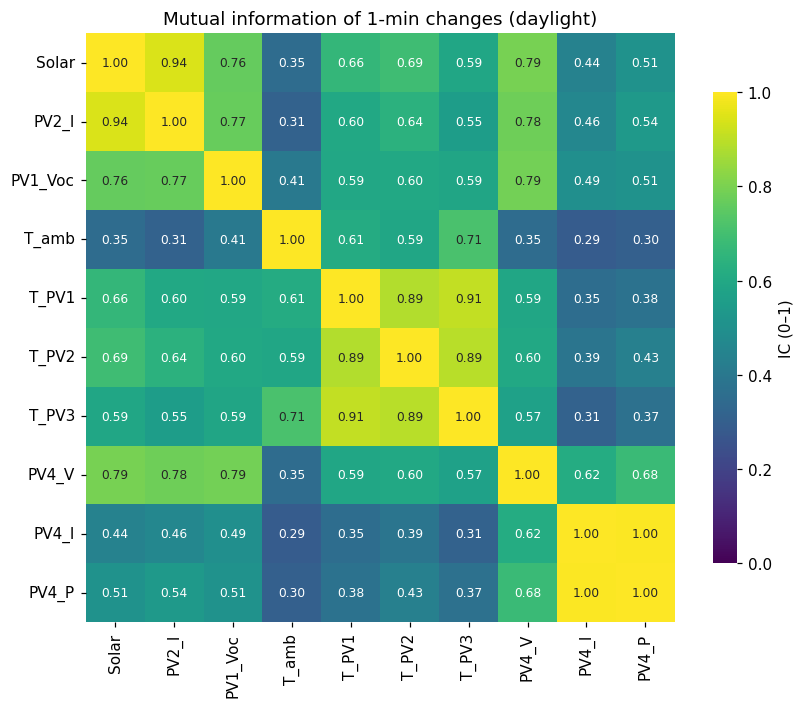

In [21]:
# Mutual information on 1-min changes (first differences remove the shared daily cycle)
names = list(m1.columns)
dZ = m1.groupby(m1.index.date).diff().dropna()          # change from previous minute, within each day
dZ = (dZ - dZ.mean()) / dZ.std()                         # standardise (kNN estimator uses distances)

mi_d = pd.DataFrame(np.nan, index=names, columns=names)
for target in names:
    mi_d.loc[:, target] = mutual_info_regression(dZ[names].values, dZ[target].values,
                                                 n_neighbors=5, random_state=0)
mi_d = (mi_d + mi_d.T) / 2                               # symmetrise estimator noise
ic_d_arr = np.sqrt(1 - np.exp(-2 * mi_d.clip(lower=0).to_numpy(dtype=float)))   # Linfoot IC (0–1)
np.fill_diagonal(ic_d_arr, 1.0)
ic_d = pd.DataFrame(ic_d_arr, index=names, columns=names)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(ic_d, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, square=True,
            cbar_kws={"shrink": 0.8, "label": "IC (0–1)"}, ax=ax, annot_kws={"size": 8})
ax.set_title("Mutual information of 1-min changes (daylight)")
ax.grid(False)
plt.tight_layout()
plt.show()

**Interpretation:**
- **Solar and PV2_I react together almost perfectly** (IC = 0.94): every cloud shows up in the PV_2 current at the same moment, so PV2_I is a direct proxy for irradiance.
- **The voltages also react quickly** to irradiance changes (`PV1_Voc` 0.76, `PV4_V` 0.79). This fits the fast electrical response of PV modules.
- **Module temperatures react only moderately** (0.59–0.69). The panels need time to heat up or cool down, so their changes lag behind irradiance (thermal inertia; Section 4).
- **The three module temperatures move together** (0.89–0.91), but not identically. `T_PV3` is the most linked to air temperature (0.71), which fits it being the coolest module.
- **Air temperature barely reacts** to short-term irradiance changes (0.31–0.35).
- **PV4 current and power are weakly linked** to everything else (0.29–0.54), as expected for a signal controlled by the battery charger. (`PV4_I`–`PV4_P` = 1.00 is trivial, since power is computed from current.)

**In short:** the electrical signals (current and voltages) respond to irradiance **almost instantly**, while temperatures respond **slowly**.

### 4. Relationships with irradiance (scatter plots)

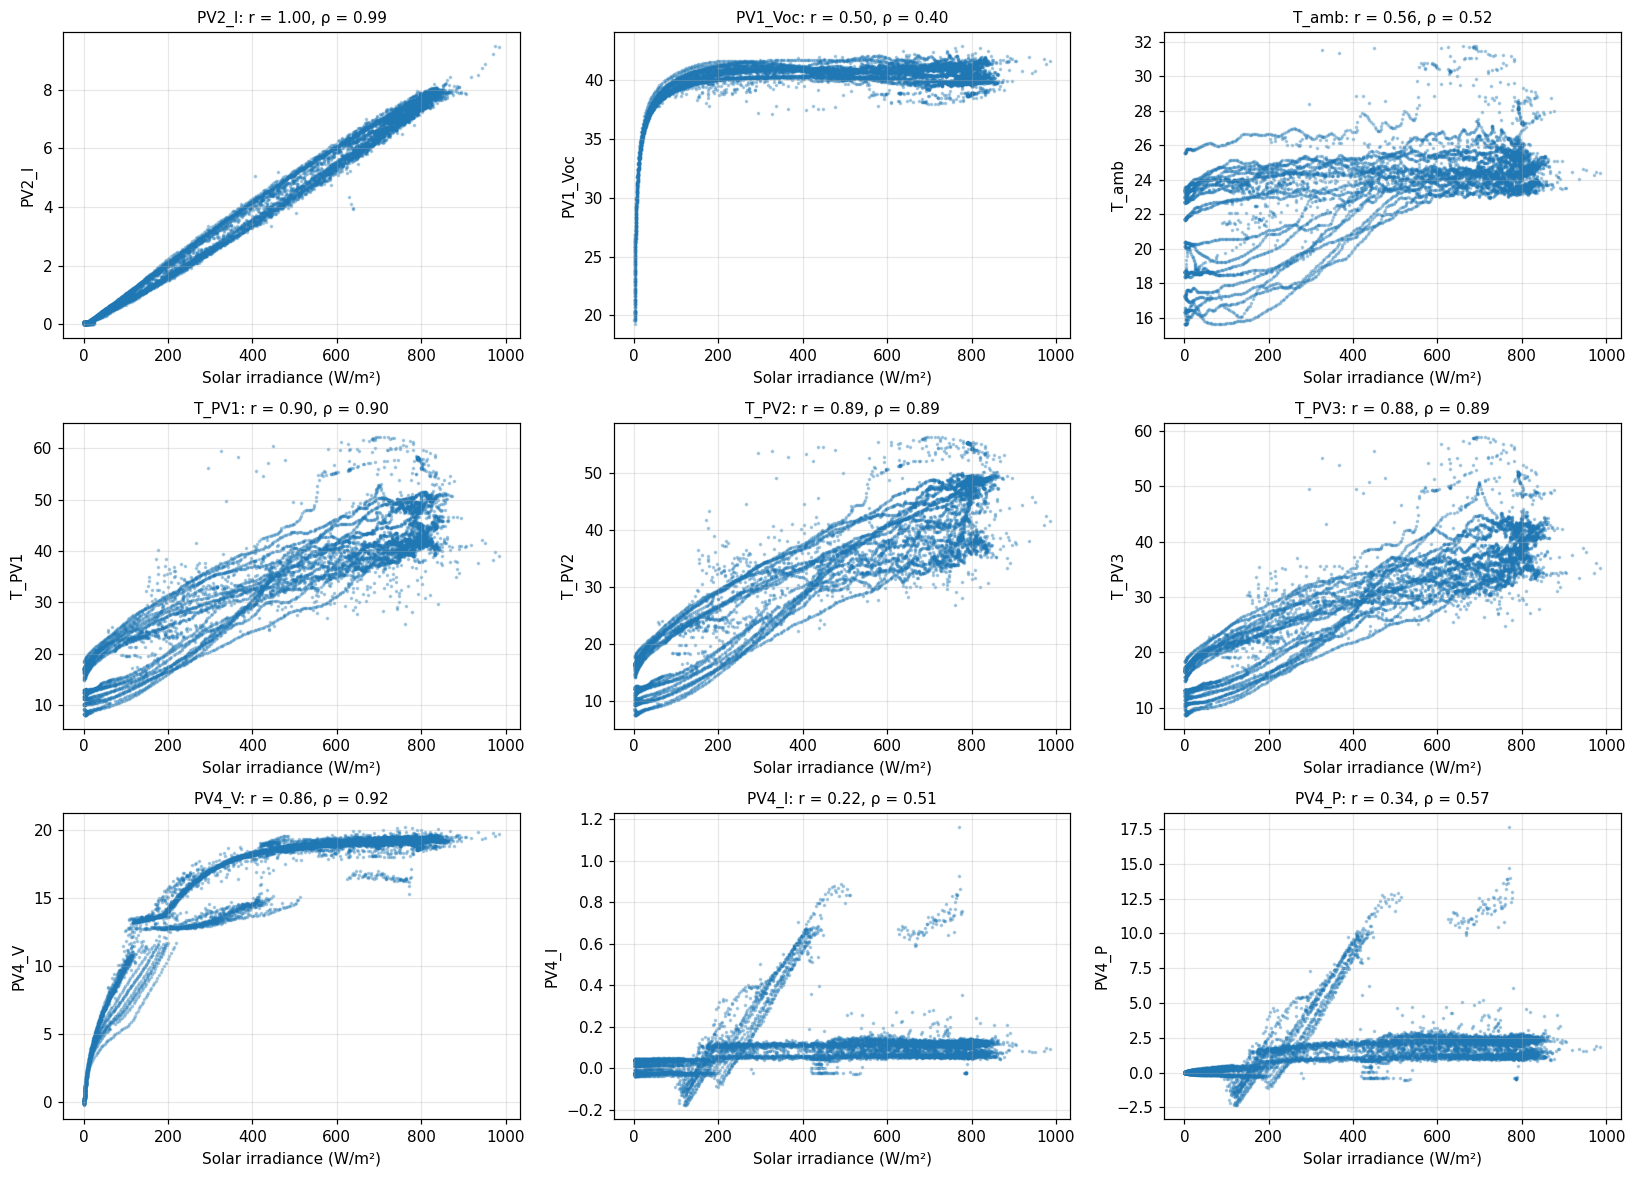

In [22]:
targets = [c for c in names if c != "Solar"]
ncols = 3
nrows = int(np.ceil(len(targets) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.6 * nrows))
for a, col in zip(axes.flat, targets):
    a.scatter(m1["Solar"], m1[col], s=2, alpha=0.3)
    a.set_xlabel("Solar irradiance (W/m²)")
    a.set_ylabel(col)
    a.set_title(f"{col}: r = {pearson.loc['Solar', col]:.2f}, ρ = {spearman.loc['Solar', col]:.2f}", fontsize=10)
for a in axes.flat[len(targets):]:
    a.set_visible(False)
plt.tight_layout()
plt.show()

### 4. Relationships with irradiance (scatter plots)

Each point is one daylight minute; each panel shows one variable against solar irradiance.

**Interpretation:**
- **PV2_I: linear and tight.** Current is proportional to irradiance, as expected. Two slightly separated bands are visible, likely morning vs afternoon, since the module and the sensor may face the sun at different angles.
- **PV1_Voc: logarithmic.** Voc rises steeply below ~100 W/m² and then levels off at ~40–41 V. This explains the modest Pearson r (0.50) despite a strong relationship. The spread at high irradiance is due to module temperature (hotter means lower Voc).
- **T_amb: weak and day-dependent.** Each day follows its own path. Air temperature depends on the day's weather more than on instantaneous irradiance.
- **T_PV1–3: increasing, with loops.** Module temperature rises with irradiance, but at the same irradiance the afternoon is warmer than the morning (separate branches). This **hysteresis** is a direct sign of thermal inertia: the module "remembers" earlier heating. The scatter at high irradiance comes from clouds and day-to-day weather.
- **PV4_V, PV4_I, PV4_P: separate regimes.** The points split into distinct branches: a rising line (charging) and a flat line (~19 V, ~0.1 A; disconnected). This regime-switching explains their low Pearson correlation and confirms control by the charge controller.

**Key point:** the module temperatures do not follow irradiance instantaneously. Their loop-shaped relationship shows that past irradiance matters.

## 5. Thermal inertia: response of temperatures to irradiance

### 5.1 Response delay

Module temperature does not respond instantly to irradiance: the module first has to heat up or cool down. We compute the correlation between each temperature at time *t* and irradiance at time *t − lag*, for lags of 0–30 min, separately within each complete day. The lag with the **highest correlation** indicates the typical response delay.

Changes (first differences) are used rather than levels, so that the result reflects the response to **irradiance fluctuations** (e.g. clouds) and is not dominated by the slow daily cycle. The **peak lag** shows how quickly each temperature starts to respond to an irradiance change.

,peak lag (min),peak correlation
T_amb,2,0.140
T_PV1,1,0.287
T_PV2,1,0.290
T_PV3,1,0.334


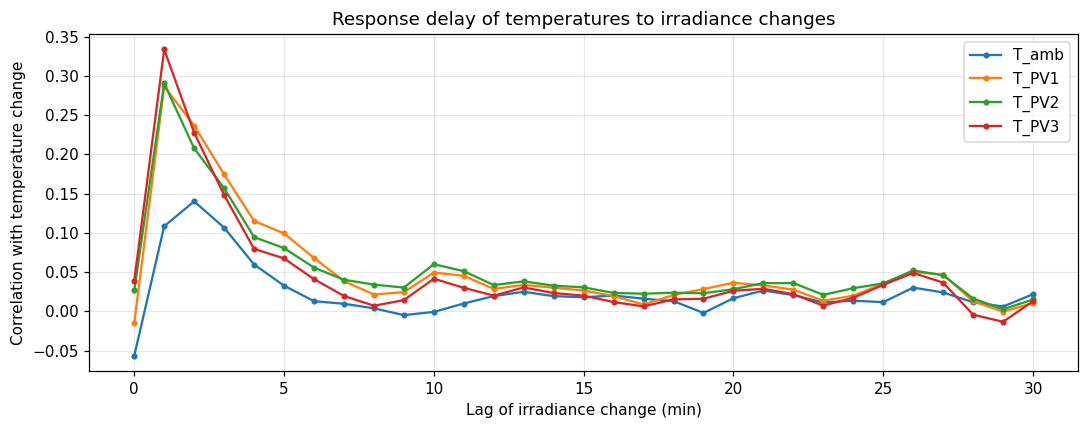

In [23]:
LAGS = range(0, 31)                        # minutes
temps = ["T_amb", "T_PV1", "T_PV2", "T_PV3"]
m1d = m1.copy()
m1d["date"] = m1d.index.date

lag_corr = pd.DataFrame(index=LAGS, columns=temps, dtype=float)
for lag in LAGS:
    g = m1d.groupby("date")
    ghi_change = g["Solar"].diff().groupby(m1d["date"]).shift(lag)          # irradiance change at t − lag
    for t in temps:
        temp_change = g[t].diff()                                         # temperature change at t
        lag_corr.loc[lag, t] = temp_change.corr(ghi_change)

best = pd.DataFrame({"peak lag (min)": lag_corr.idxmax(), "peak correlation": lag_corr.max()}).round(3)
display(best)

ax = lag_corr.plot(figsize=(10, 4), marker="o", ms=3)
ax.set_xlabel("Lag of irradiance change (min)")
ax.set_ylabel("Correlation with temperature change")
ax.set_title("Response delay of temperatures to irradiance changes")
plt.tight_layout()
plt.show()

**Interpretation:**
- **Module temperatures respond within about 1 minute.** For all three modules the correlation is ~0 at lag 0 and peaks at **lag 1 min** (r = 0.29–0.33). In other words, an irradiance change is followed by a temperature change in the next minute, not in the same minute.
- **The effect lasts several minutes.** After the peak, the correlation decays gradually and approaches zero after **~7–8 min**. This means a single cloud passage keeps affecting module temperature for several minutes, which is typical first-order thermal behaviour (quantified as a time constant in Section 5.2).
- **T_PV3 responds most strongly** (0.33), consistent with it being the most exposed or least thermally damped of the three sensors.
- **Air temperature responds weakly and slightly later** (peak 0.14 at 2 min), and the effect fades within ~5 min. The air near the site is only slightly affected by passing clouds.
- **Why the correlations are moderate (≤ 0.33):** the temperature response is spread over several minutes rather than concentrated at one lag, and temperature changes are also driven by factors not measured here (e.g. wind). The small bumps beyond 10 min (≤ 0.05) are negligible.

**Key point:** module temperatures react to irradiance changes **with a delay of ~1 min and a memory of several minutes**. A model that predicts temperature only from *current* irradiance (steady-state) will therefore miss this behaviour.

### 5.2 Thermal time constant of the modules

A PV module behaves approximately like a **first-order thermal system**: after a step change in irradiance, its temperature approaches the new equilibrium exponentially, with a characteristic **time constant τ** (literature: ~6 min for fixed-mount modules).

To estimate τ, irradiance is passed through an exponential filter with time constant τ (a "memory" of past irradiance) and the module temperature is regressed on ambient temperature and the filtered irradiance:

T_module(t) = a + b·T_amb(t) + c·GHI_filtered,τ(t)

The τ giving the **best fit (highest R²)** is the estimated thermal time constant. τ = 0 corresponds to the standard steady-state models (no memory).

,best τ (min),R² at best τ,R² steady-state (τ = 0)
T_PV1,7,0.940,0.926
T_PV2,12,0.937,0.917
T_PV3,5,0.924,0.914


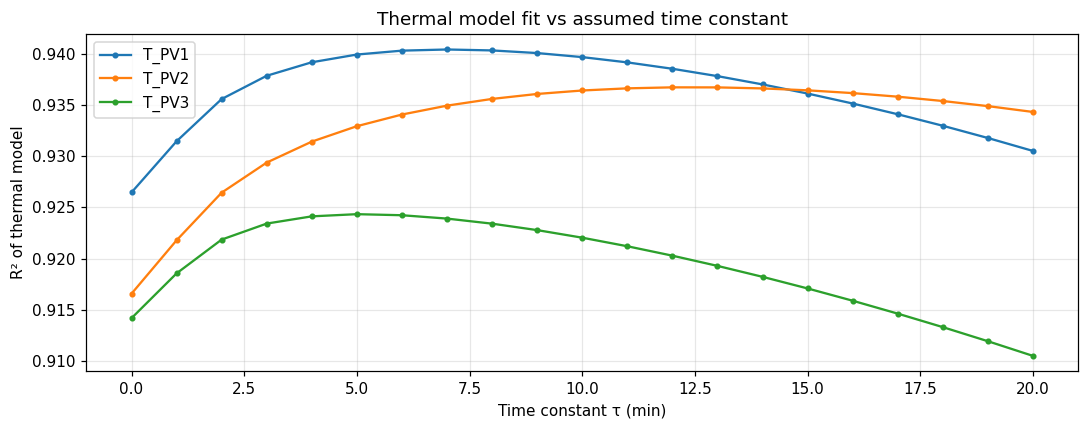

In [24]:
TAUS = range(0, 21)                         # minutes
fits = pd.DataFrame(index=TAUS, columns=["T_PV1", "T_PV2", "T_PV3"], dtype=float)
for tau in TAUS:
    if tau == 0:
        g_f = m1d["Solar"]
    else:
        alpha = 1 - np.exp(-1 / tau)
        g_f = m1d.groupby("date")["Solar"].transform(lambda s: s.ewm(alpha=alpha, adjust=False).mean())
    X = np.column_stack([np.ones(len(m1d)), m1d["T_amb"], g_f])
    for t in fits.columns:
        y = m1d[t].to_numpy()
        coef, *_ = np.linalg.lstsq(X, y, rcond=None)
        fits.loc[tau, t] = 1 - ((y - X @ coef) ** 2).sum() / ((y - y.mean()) ** 2).sum()

tau_table = pd.DataFrame({"best τ (min)": fits.idxmax(), "R² at best τ": fits.max(),
                          "R² steady-state (τ = 0)": fits.loc[0]}).round(3)
display(tau_table)

ax = fits.plot(figsize=(10, 4), marker="o", ms=3)
ax.set_xlabel("Time constant τ (min)")
ax.set_ylabel("R² of thermal model")
ax.set_title("Thermal model fit vs assumed time constant")
plt.tight_layout()
plt.show()

**Interpretation:**

| Module | Best τ (min) | R² steady-state (τ = 0) | R² at best τ | Unexplained variance |
|---|---|---|---|---|
| T_PV1 | 7 | 0.926 | 0.940 | 7.4% → 6.0% (−19%) |
| T_PV2 | 12 | 0.917 | 0.937 | 8.3% → 6.3% (−24%) |
| T_PV3 | 5 | 0.914 | 0.924 | 8.6% → 7.6% (−12%) |

- **The modules have thermal time constants of about 5–12 min**, in line with the ~6 min reported in the literature for fixed-mount modules. This confirms that module temperature depends on irradiance over the **past several minutes**, not only on the current value.
- **Adding thermal memory improves every model.** The gain in R² looks small (+0.010 to +0.020) because the daily cycle dominates R². In terms of the variance the steady-state model cannot explain, however, the error drops by **12–24%**.
- **The modules differ:** T_PV2 responds most slowly (τ ≈ 12 min), T_PV3 fastest (τ ≈ 5 min). This is consistent with T_PV3 being the coolest module and the most coupled to air temperature (Section 3), e.g. due to better ventilation or a different mounting.
- **τ is an approximate value:** the curves are flat near their maximum (e.g. for T_PV2, R² changes by < 0.001 between 9 and 15 min), so each τ is uncertain by a few minutes.
- **About 6–8% of the variance remains unexplained** even with the best τ. It probably comes from factors this simple model does not include, such as wind, sky temperature and non-linear heat exchange. This is the part a data-driven (deep learning) model could capture.

**Key point:** a simple first-order thermal model with τ ≈ 5–12 min outperforms the steady-state approach for all modules, and the remaining error leaves room for a physics-guided deep learning model.